# Ejercicio 1 — Predicción del precio del dólar

**Laboratorio de Minería de Datos — metodología CRISP-DM**

Fases: 1) comprensión del negocio · 2) comprensión de los datos · 3) preparación · 4) modelado · 5) evaluación · 6) despliegue (exportación del modelo e interfaz web).

## 1. Comprensión del negocio

Se quiere estimar el **precio del dólar** (`Precio_Dolar`, en pesos colombianos) a partir de tres variables:

| Variable | Significado |
|---|---|
| `Dia` | Número de día de la serie (1, 2, 3, …) |
| `Inflacion` | Tasa de inflación diaria, como fracción (0,02 = 2 %) |
| `Tasa_interes` | Tasa de interés diaria, en porcentaje |

**Preguntas a responder:** ¿qué tan bien predice un modelo de regresión lineal múltiple el precio del dólar?, ¿cómo afecta cada variable al precio?, y ¿cuál es su MSE y su R²?

In [1]:
# Configuración del ejercicio
ARCHIVO = "dolar_data.csv"
PREFIJO = "dolar"
OBJETIVO = "Precio_Dolar"
VARIABLES = ["Dia", "Inflacion", "Tasa_interes"]
UNIDAD = "COP"
# Cambio realista de cada variable para leer su coeficiente
PASOS = {
    "Dia": (1, "1 día más"),
    "Inflacion": (0.01, "1 punto porcentual más de inflación (+0,01)"),
    "Tasa_interes": (1, "1 punto más de tasa de interés"),
}

In [2]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS = RAIZ / "data"
MODELOS = RAIZ / "modelos"
FIGURAS = RAIZ / "figuras"
MODELOS.mkdir(exist_ok=True)
FIGURAS.mkdir(exist_ok=True)

SEMILLA = 42  # misma partición de datos cada vez que se ejecuta
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", "{:,.4f}".format)

## 2. Comprensión de los datos

In [3]:
df = pd.read_csv(DATOS / ARCHIVO)
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 500 | Columnas: 4


,Dia,Inflacion,Tasa_interes,Precio_Dolar
0,1,0.0225,5.4631,"4,024.8336"
1,2,0.0193,5.9547,"4,000.5463"
2,3,0.0232,4.3007,"3,979.6220"
3,4,0.0276,5.2815,"3,940.3613"
4,5,0.0188,4.6747,"4,016.9302"


In [4]:
print("Tipos de dato:")
print(df.dtypes.to_string())
print("\nValores nulos por columna:")
print(df.isna().sum().to_string())
print(f"\nFilas duplicadas: {df.duplicated().sum()}")

Tipos de dato:
Dia               int64
Inflacion       float64
Tasa_interes    float64
Precio_Dolar    float64

Valores nulos por columna:
Dia             0
Inflacion       0
Tasa_interes    0
Precio_Dolar    0

Filas duplicadas: 0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Dia,500.0000,250.5000,144.4818,1.0000,125.7500,250.5000,375.2500,500.0000
Inflacion,500.0000,0.0200,0.0049,0.0038,0.0165,0.0201,0.0232,0.0393
Tasa_interes,500.0000,5.0159,0.4890,3.6516,4.7024,5.0143,5.3256,6.3162
Precio_Dolar,500.0000,"5,211.7719",723.8952,"3,940.3613","4,604.8850","5,218.7911","5,825.2353","6,553.5986"


### Correlación entre variables

El coeficiente de correlación de Pearson (r) va de −1 a 1 y mide qué tan lineal es la relación entre dos variables.

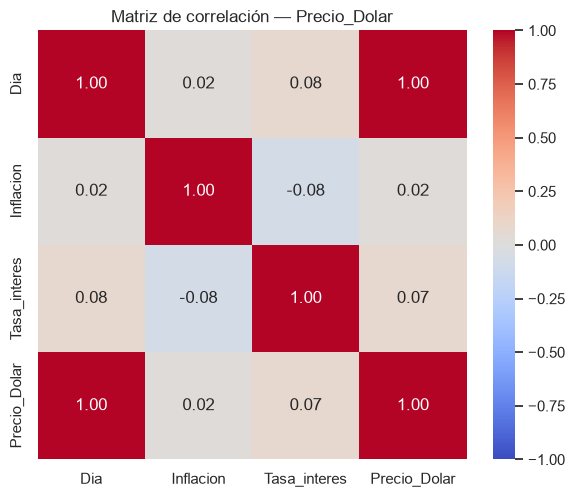

,r con Precio_Dolar
Dia,0.9976
Tasa_interes,0.0743
Inflacion,0.0196


In [6]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title(f"Matriz de correlación — {OBJETIVO}")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_correlacion.png", dpi=150); plt.show()

corr[OBJETIVO].drop(OBJETIVO).sort_values(key=abs, ascending=False).rename(f"r con {OBJETIVO}").to_frame()

## 3. Preparación de los datos

Se revisan valores atípicos con la regla del rango intercuartílico (IQR): un valor es atípico si está por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR.

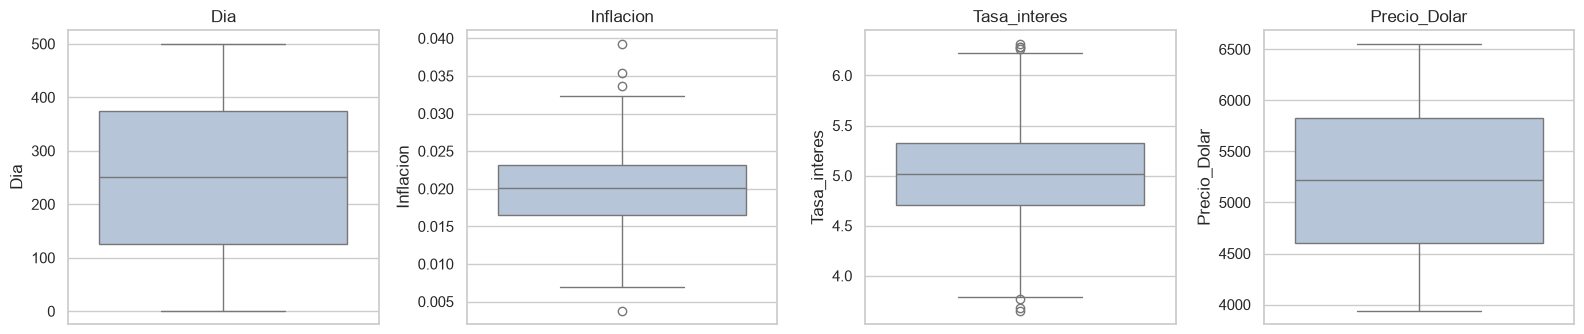

,atípicos (IQR),mínimo,máximo
Dia,0,1.0000,500.0000
Inflacion,4,0.0038,0.0393
Tasa_interes,7,3.6516,6.3162
Precio_Dolar,0,"3,940.3613","6,553.5986"


In [7]:
def contar_atipicos_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())


atipicos = pd.DataFrame({
    "atípicos (IQR)": {c: contar_atipicos_iqr(df[c]) for c in df.columns},
    "mínimo": df.min(),
    "máximo": df.max(),
})

fig, ejes = plt.subplots(1, len(df.columns), figsize=(4 * len(df.columns), 3.5))
for ax, columna in zip(ejes, df.columns):
    sns.boxplot(y=df[columna], ax=ax, color="lightsteelblue")
    ax.set_title(columna)
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_cajas.png", dpi=150); plt.show()
atipicos

**Decisión de limpieza:** el dataset no tiene valores nulos ni filas duplicadas. La regla IQR marca 4 valores de `Inflacion` y 7 de `Tasa_interes`, pero todos están en rangos económicamente posibles (inflación entre 0,4 % y 3,9 %, tasa entre 3,65 % y 6,32 %). No son errores de captura sino días con valores altos o bajos, así que **se conservan las 500 filas**.

### Partición entrenamiento / prueba

El 80 % de las filas se usa para entrenar y el 20 % se guarda para evaluar con datos que el modelo no ha visto.

In [8]:
X = df[VARIABLES]
y = df[OBJETIVO]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_train):,} filas | Prueba: {len(X_test):,} filas")

Entrenamiento: 400 filas | Prueba: 100 filas


## 4. Modelado — regresión lineal múltiple

El modelo tiene la forma  ŷ = β₀ + β₁·x₁ + β₂·x₂ + β₃·x₃  y se ajusta por mínimos cuadrados ordinarios con `scikit-learn`.

In [9]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

terminos = " ".join(f"{'+' if c >= 0 else '-'} {abs(c):,.4f}·{v}" for v, c in zip(VARIABLES, modelo.coef_))
print("Ecuación del modelo:")
print(f"{OBJETIVO} = {modelo.intercept_:,.4f} {terminos}")

Ecuación del modelo:
Precio_Dolar = 3,985.7833 + 4.9843·Dia - 870.7317·Inflacion - 1.3774·Tasa_interes


Se ajusta el mismo modelo con `statsmodels` para obtener los **p-valores** (si un coeficiente es estadísticamente distinto de cero) y el **VIF** (multicolinealidad: un VIF mayor que 5 indica que las variables se solapan entre sí).

In [10]:
X_train_const = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_const).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:           Precio_Dolar   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                 2.504e+04
Date:                Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:29:11   Log-Likelihood:                -2138.7
No. Observations:                 400   AIC:                             4285.
Df Residuals:                     396   BIC:                             4301.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         3985.7833     29.391    135.613   

In [11]:
vif = pd.Series(
    [variance_inflation_factor(X_train_const.values, i) for i in range(1, X_train_const.shape[1])],
    index=VARIABLES,
    name="VIF",
)
vif.to_frame()

,VIF
Dia,1.0082
Inflacion,1.0038
Tasa_interes,1.0108


## 5. Evaluación del modelo

In [12]:
def metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_real, y_pred), "R2": r2_score(y_real, y_pred)}


pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)
m_train = metricas(y_train, pred_train)
m_test = metricas(y_test, pred_test)

kfold = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
r2_cv = cross_val_score(LinearRegression(), X, y, cv=kfold, scoring="r2")

pd.DataFrame({"Entrenamiento": m_train, "Prueba": m_test}).rename(index={"R2": "R²"})

,Entrenamiento,Prueba
MSE,"2,580.4620","2,376.9709"
RMSE,50.7982,48.7542
MAE,40.4687,37.0065
R²,0.9948,0.9963


In [13]:
print(f"R² con validación cruzada (5 pliegues): {r2_cv.mean():.4f} ± {r2_cv.std():.4f}\n")
print(f"• El modelo explica el {m_test['R2']:.1%} de la variación de {OBJETIVO} en datos que no vio al entrenar.")
print(f"• MSE = {m_test['MSE']:,.2f} ({UNIDAD})²: promedio de los errores al cuadrado.")
print(f"• RMSE = {m_test['RMSE']:,.2f} {UNIDAD}: error típico en las unidades originales "
      f"({m_test['RMSE'] / y.mean():.1%} del promedio de {OBJETIVO}, que es {y.mean():,.2f} {UNIDAD}).")
print(f"• MAE = {m_test['MAE']:,.2f} {UNIDAD}: en promedio la predicción se aleja eso del valor real.")
diferencia = m_train["R2"] - m_test["R2"]
print(f"• R² entrenamiento − R² prueba = {diferencia:+.4f} → "
      + ("no hay señales de sobreajuste." if abs(diferencia) < 0.05 else "revisar posible sobreajuste."))

R² con validación cruzada (5 pliegues): 0.9949 ± 0.0011

• El modelo explica el 99.6% de la variación de Precio_Dolar en datos que no vio al entrenar.
• MSE = 2,376.97 (COP)²: promedio de los errores al cuadrado.
• RMSE = 48.75 COP: error típico en las unidades originales (0.9% del promedio de Precio_Dolar, que es 5,211.77 COP).
• MAE = 37.01 COP: en promedio la predicción se aleja eso del valor real.
• R² entrenamiento − R² prueba = -0.0016 → no hay señales de sobreajuste.


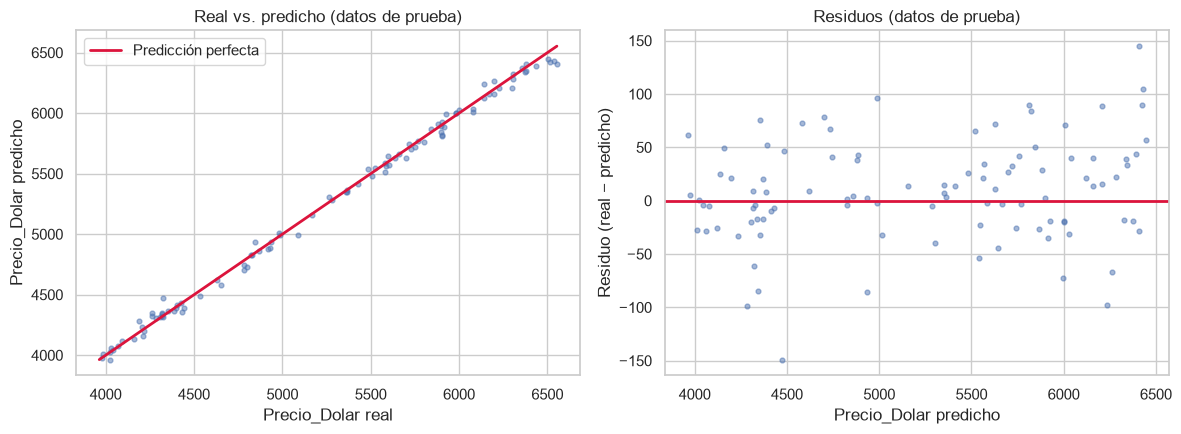

In [14]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
ejes[0].scatter(y_test, pred_test, alpha=0.5, s=12)
limites = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ejes[0].plot(limites, limites, color="crimson", lw=2, label="Predicción perfecta")
ejes[0].set(xlabel=f"{OBJETIVO} real", ylabel=f"{OBJETIVO} predicho", title="Real vs. predicho (datos de prueba)")
ejes[0].legend()

residuos = y_test - pred_test
ejes[1].scatter(pred_test, residuos, alpha=0.5, s=12)
ejes[1].axhline(0, color="crimson", lw=2)
ejes[1].set(xlabel=f"{OBJETIVO} predicho", ylabel="Residuo (real − predicho)", title="Residuos (datos de prueba)")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_evaluacion.png", dpi=150); plt.show()

### Interpretación de los coeficientes e importancia de cada variable

- **Coeficiente:** cuánto cambia la predicción cuando la variable sube una unidad y las demás se mantienen fijas.
- **Coeficiente estandarizado (β):** el mismo efecto medido en desviaciones estándar; como no depende de las unidades, permite **comparar qué variable pesa más**.
- **Efecto en el rango típico:** cuánto cambia la predicción al pasar la variable de su percentil 25 a su percentil 75 (el 50 % central de los datos).

In [15]:
desv_y = y_train.std()
coeficientes = pd.DataFrame({
    "coeficiente": modelo.coef_,
    "coef_estandarizado": [c * X_train[v].std() / desv_y for v, c in zip(VARIABLES, modelo.coef_)],
    "efecto_rango_típico": [c * (X[v].quantile(0.75) - X[v].quantile(0.25)) for v, c in zip(VARIABLES, modelo.coef_)],
    "p_valor": ols.pvalues[VARIABLES].values,
}, index=VARIABLES)
coeficientes["importancia_%"] = 100 * coeficientes["coef_estandarizado"].abs() / coeficientes["coef_estandarizado"].abs().sum()
coeficientes = coeficientes.sort_values("importancia_%", ascending=False)
coeficientes

,coeficiente,coef_estandarizado,efecto_rango_típico,p_valor,importancia_%
Dia,4.9843,0.9976,"1,243.5925",0.0000,99.3008
Inflacion,-870.7317,-0.0061,-5.8212,0.0960,0.6056
Tasa_interes,-1.3774,-0.0009,-0.8585,0.7972,0.0936


In [16]:
print(f"Intercepto (β₀) = {modelo.intercept_:,.4f} {UNIDAD}: valor teórico de {OBJETIVO} si todas las variables valieran 0.\n")
for variable, fila in coeficientes.iterrows():
    paso, texto = PASOS[variable]
    efecto = fila["coeficiente"] * paso
    direccion = "sube" if efecto >= 0 else "baja"
    significancia = "significativo" if fila["p_valor"] < 0.05 else "NO significativo"
    print(f"• {variable}: con {texto}, {OBJETIVO} {direccion} {abs(efecto):,.4f} {UNIDAD}, "
          f"manteniendo fijas las demás variables.")
    print(f"  p-valor = {fila['p_valor']:.3g} ({significancia} al 5 %) | importancia relativa = {fila['importancia_%']:.1f} %\n")
print(f"Variable con MAYOR impacto: {coeficientes.index[0]} "
      f"(β estandarizado = {coeficientes['coef_estandarizado'].iloc[0]:+.3f}).")

Intercepto (β₀) = 3,985.7833 COP: valor teórico de Precio_Dolar si todas las variables valieran 0.

• Dia: con 1 día más, Precio_Dolar sube 4.9843 COP, manteniendo fijas las demás variables.
  p-valor = 0 (significativo al 5 %) | importancia relativa = 99.3 %

• Inflacion: con 1 punto porcentual más de inflación (+0,01), Precio_Dolar baja 8.7073 COP, manteniendo fijas las demás variables.
  p-valor = 0.096 (NO significativo al 5 %) | importancia relativa = 0.6 %

• Tasa_interes: con 1 punto más de tasa de interés, Precio_Dolar baja 1.3774 COP, manteniendo fijas las demás variables.
  p-valor = 0.797 (NO significativo al 5 %) | importancia relativa = 0.1 %

Variable con MAYOR impacto: Dia (β estandarizado = +0.998).


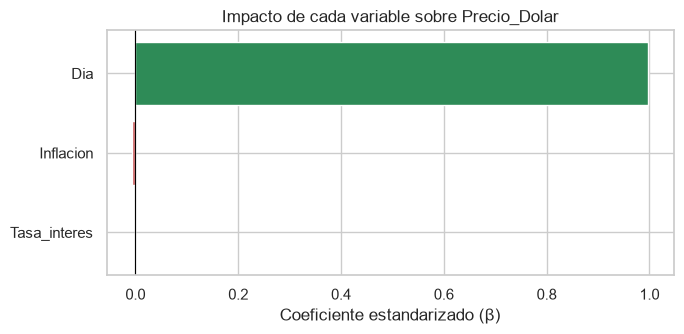

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.5))
orden = coeficientes.iloc[::-1]
colores = ["seagreen" if c >= 0 else "indianred" for c in orden["coef_estandarizado"]]
ax.barh(orden.index, orden["coef_estandarizado"], color=colores)
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Coeficiente estandarizado (β)", title=f"Impacto de cada variable sobre {OBJETIVO}")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_importancia.png", dpi=150); plt.show()

## 6. Relación de cada variable independiente con la variable dependiente

Cada punto es una observación. La línea roja es la recta de regresión simple de esa variable sola contra la variable dependiente.

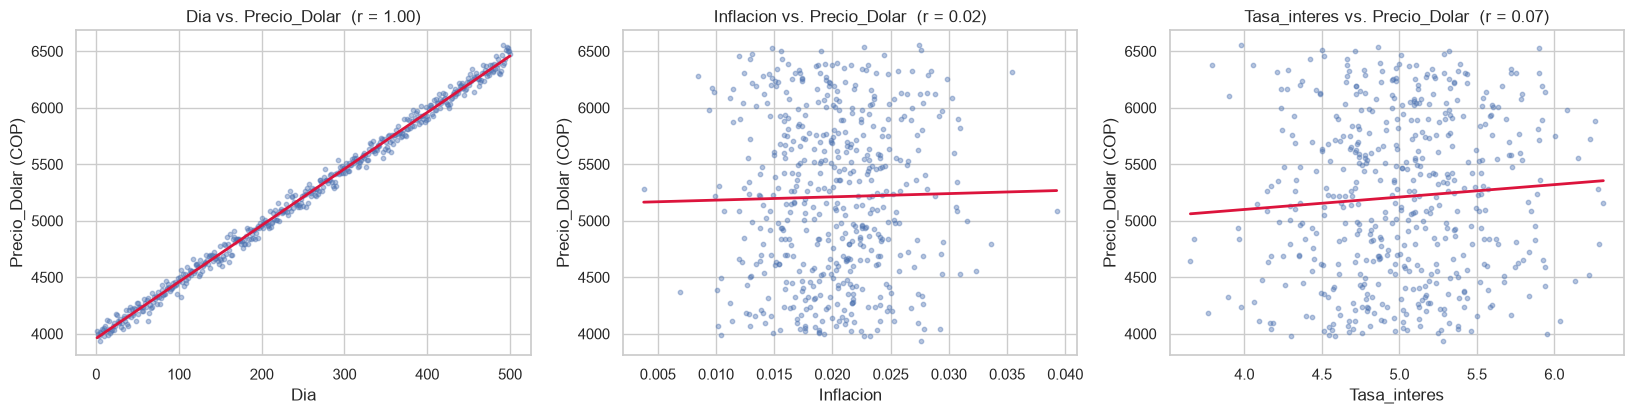

In [18]:
fig, ejes = plt.subplots(1, len(VARIABLES), figsize=(5.5 * len(VARIABLES), 4.3))
transparencia = 0.15 if len(df) > 5000 else 0.4
for ax, variable in zip(ejes, VARIABLES):
    ax.scatter(df[variable], df[OBJETIVO], alpha=transparencia, s=10)
    pendiente, corte = np.polyfit(df[variable], df[OBJETIVO], 1)
    xs = np.linspace(df[variable].min(), df[variable].max(), 100)
    ax.plot(xs, corte + pendiente * xs, color="crimson", lw=2)
    r = df[variable].corr(df[OBJETIVO])
    ax.set(xlabel=variable, ylabel=f"{OBJETIVO} ({UNIDAD})", title=f"{variable} vs. {OBJETIVO}  (r = {r:.2f})")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_dispersion.png", dpi=150); plt.show()

## 7. Exportación del modelo

En Python hay dos formas habituales de guardar un modelo entrenado:

| | `pickle` | `joblib` |
|---|---|---|
| Qué es | Módulo estándar de Python | Librería que usa scikit-learn |
| Guardar | `pickle.dump(obj, open("m.pkl", "wb"))` | `joblib.dump(obj, "m.joblib")` |
| Cargar | `pickle.load(open("m.pkl", "rb"))` | `joblib.load("m.joblib")` |
| Ventaja | No requiere instalar nada | Más eficiente con arreglos grandes de NumPy |

Se usa **joblib**, que es lo que recomienda la documentación de scikit-learn. Junto al modelo se guardan las variables, las métricas, los coeficientes y los rangos de los datos, para que la interfaz web pueda mostrarlos. Solo se guardan objetos de scikit-learn y tipos básicos de Python, así que la app no necesita el código de este notebook para cargarlo. Al cargarlo se debe usar la **misma versión de scikit-learn** (queda registrada en el archivo).

In [19]:
artefacto = {
    "modelo": modelo,
    "variables": VARIABLES,
    "objetivo": OBJETIVO,
    "unidad": UNIDAD,
    "intercepto": float(modelo.intercept_),
    "coeficientes": {v: float(c) for v, c in zip(VARIABLES, modelo.coef_)},
    "coef_estandarizados": coeficientes["coef_estandarizado"].astype(float).to_dict(),
    "p_valores": coeficientes["p_valor"].astype(float).to_dict(),
    "metricas_prueba": {k: float(v) for k, v in m_test.items()},
    "metricas_entrenamiento": {k: float(v) for k, v in m_train.items()},
    "r2_validacion_cruzada": {"media": float(r2_cv.mean()), "desviacion": float(r2_cv.std())},
    "rangos": {
        v: {"min": float(df[v].min()), "max": float(df[v].max()), "mediana": float(df[v].median())}
        for v in VARIABLES
    },
    "filas": {"entrenamiento": len(X_train), "prueba": len(X_test)},
    "version_sklearn": sklearn.__version__,
}

ruta_modelo = MODELOS / f"modelo_{PREFIJO}.joblib"
joblib.dump(artefacto, ruta_modelo)
print(f"Modelo guardado en {ruta_modelo.relative_to(RAIZ)} ({ruta_modelo.stat().st_size / 1024:.1f} KB)")

Modelo guardado en modelos\modelo_dolar.joblib (1.6 KB)


Se carga el archivo de nuevo y se comprueba que predice exactamente lo mismo que el modelo original:

In [20]:
cargado = joblib.load(ruta_modelo)
ejemplo = X_test.head(5)
comparacion = ejemplo.copy()
comparacion[f"{OBJETIVO} real"] = y_test.head(5).values
comparacion["predicción (modelo original)"] = modelo.predict(ejemplo)
comparacion["predicción (modelo cargado)"] = cargado["modelo"].predict(ejemplo)
assert np.allclose(comparacion["predicción (modelo original)"], comparacion["predicción (modelo cargado)"])
comparacion

,Dia,Inflacion,Tasa_interes,Precio_Dolar real,predicción (modelo original),predicción (modelo cargado)
361,362,0.0277,4.2421,"5,802.0760","5,760.1830","5,760.1830"
73,74,0.0278,4.8904,"4,262.5105","4,323.6615","4,323.6615"
374,375,0.0308,4.9834,"5,904.8773","5,821.2571","5,821.2571"
155,156,0.0164,5.0296,"4,783.4804","4,742.1076","4,742.1076"
104,105,0.0192,5.2067,"4,532.1807","4,485.2545","4,485.2545"


## 8. Conclusiones

1. **Desempeño:** el modelo explica el **99,6 %** de la variación del precio del dólar en los datos de prueba (R² = 0,9963), con un **MSE de 2.376,97** y un RMSE de 48,75 COP, menos del 1 % del precio promedio (5.211,77 COP). El R² de entrenamiento (0,9948) y el de validación cruzada (0,9949 ± 0,0011) son casi iguales: no hay sobreajuste.
2. **Interpretación de los coeficientes:**
   - `Dia` (+4,98 COP por día): es la variable que explica el precio. El dólar sube en promedio unos 5 pesos diarios; a lo largo de los 500 días eso son unos 2.490 COP.
   - `Inflacion` (−8,71 COP por cada punto porcentual): el efecto es pequeño y **no es estadísticamente significativo** (p = 0,096 > 0,05).
   - `Tasa_interes` (−1,38 COP por punto): tampoco es significativa (p = 0,797).
3. **Importancia:** el día concentra el 99,3 % del impacto (correlación r = 0,998). La inflación y la tasa de interés casi no se relacionan con el precio en estos datos (r = 0,02 y r = 0,07).
4. **Multicolinealidad:** los VIF son cercanos a 1, así que las tres variables son independientes entre sí y los coeficientes se pueden interpretar uno por uno.
5. **Limitación:** el modelo es, en la práctica, una tendencia en el tiempo. Predice bien dentro de los días observados (1 a 500), pero extrapolar a días futuros supone que la tendencia se mantiene igual.